# Practical 4: Atomistic Simulation

**Course:** Materials Simulation Practical  
**Supervisor:** M.Sc. Zhipeng Yao  
**Chair:** Chair of Materials Simulation (WW8)  
**Student:** Huseyn Shahhuseynov

<br><br>

## Task 2.1

### 1. Many-Body vs Two-Body Interactions:

Effective-Medium Theory (EMT) and the Embedded Atom Method (EAM) are many-body potentials, whereas a simple pair potential like Lennard-Jones (LJ) includes only two-body interactions. In EMT/EAM, the energy per atom depends on the local environment density (electron density or neighbor density) in addition to pairwise distances. For example, EAM assigns each atom an embedding energy that is a function of the host electron density contributed by neighbors, plus a pairwise term. In contrast, a pair potential like LJ sums energies for each atom pair independent of other neighbors. This means EMT/EAM implicitly include multi-atom effects (bond order or cohesion changing with coordination), whereas pair potentials assume fixed two-atom interaction regardless of environment [1].

<br><br>

### 2. Limitations for Metals:

Simple pair potentials like LJ are generally not suitable for metals such as copper because metallic bonding is fundamentally a many-body phenomenon. Metals have a delocalized electron gas; the bond energy of an atom depends on all its neighbors collectively, not just on individual pairs. A pair potential cannot capture effects like the dependence of cohesion on coordination number or the correct energy difference between various crystal structures. For instance, with a pair potential one usually cannot simultaneously fit a metal’s cohesive energy, equilibrium lattice parameter, and elastic constants, and the functional form is too restrictive. Furthermore, the pairwise potentials automatically obey certain elastic relations that real metals do not (Cauchy relations), meaning a simple pair potential will predict incorrect relative values of elastic constants for copper. They also fail to predict the correct vacancy formation energies or surface energies for metals, because removing one neighbor in a metal has a non-linear effect on bonding that pair potentials can’t reproduce [5].

In essence, metals require potentials (like EMT, EAM, or other multi-body potentials) where bond strength is environment-dependent. The only real advantages of pair potentials are their simplicity and computational efficiency. A pair potential (like LJ or Morse) has very few parameters and a simple functional form, making it easy to implement and fast to compute. Moreover, having fewer parameters means they are easier to fit for those properties they can reproduce (often just equilibrium distance and bonding energy). However, this simplicity comes at the cost of realism for metals [5].


### 3. Parameter Fitting: Pair Potentials vs. Semi-Empirical Potentials:

- Pair Potentials (e.g. LJ, Morse): These have very few parameters (two for LJ: $\sigma$ and $\epsilon$). Fitting is straightforward but limited – typically one chooses parameters to match basic properties such as the equilibrium bond distance (or lattice constant) and cohesive energy of the metal. For example, the LJ well depth $\epsilon$ might be set to reproduce copper’s cohesive energy and $\sigma$ to get the correct nearest-neighbor distance. However, once these two are fixed, all other predictions are determined. There is no flexibility to independently tune the bulk modulus, elastic constants, defect energies, etc. As a result, pair potentials cannot simultaneously fit multiple target properties for a metal; any fit is a compromise. They often end up with incorrect elastic moduli or thermal behavior because the functional form is too restrictive. In essence, with pair functions a good fit to one property can force wrong values for others (e.g. a Lennard-Jones potential fitted to Cu’s cohesion and lattice will typically give an incorrect bulk modulus and melting point) [2].

<br><br>

- Semi-empirical Many-Body Potentials (EMT/EAM): These models have more parameters and sometimes functional forms that can be adjusted, so fitting them is more involved but also more powerful. Typically, EAM/EMT parameters is fitted to a large database of experimental or ab initio data: not only the equilibrium lattice constant and cohesive energy, but also elastic constants ($C_{11}, C_{12}, C_{44}$), vacancy formation energies, stacking fault energies, surface energies, etc. This multi-objective fitting is often done with non-linear optimization algorithms to minimize error against many target properties. The presence of the embedding function and pair function in EAM means there are several functions (often represented by tabulated values or splines with adjustable parameters) that can be tuned. For example, the shape of the electron-density function or embedding energy curve can be adjusted to get the correct bulk modulus without altering the equilibrium lattice parameter. As a result, EAM potentials can be made to reproduce a broad set of a metal’s properties fairly well. The downside is the fitting process is complex – there may be dozens of parameters, and fitting requires careful attention to avoid overfitting one property at the expense of others. In practice, published EAM potentials for Cu (such as the Mishin et al. 2001 potential mentioned below) use on the order of 8–10 adjustable parameters and have been optimized to reproduce many properties of copper simultaneously. This yields a more transferable potential [4].

<br><br>

### 4. Copper Potential Parameters in ASE

For THE copper lattice simulations, we can rely on parameter sets developed by others. Below recommended parameters for copper for a Lennard-Jones pair potential, the Effective Medium Theory (EMT) potential, and an Embedded-Atom Method (EAM) potential are summorized, along with notes on using them in the Atomic Simulation Environment (ASE):

- Lennard-Jones (12–6) Pair Potential for Cu: Although not physically ideal for metals, a Lennard-Jones potential can be parameterized for copper for demonstration. Reported LJ parameters for Cu (often used in pedagogical contexts) are $\epsilon = 0.583~\text{eV}$ (depth of the potential well) and $\sigma = 0.227~\text{nm}$ (distance at which the potential crosses zero). These values yield a reasonable approximation to copper’s cohesion and atomic spacing (Cu has an fcc lattice with nearest-neighbor distance $\sim0.256$ nm and cohesive energy $\sim3.5$ eV). In ASE, one can use the built-in LennardJones calculator by specifying these parameters [2]. For example, in a Python script:

<br><br>

---

from ase.calculators.lj import LennardJones  
calc = LennardJones(sigma=0.227, epsilon=0.583, rc=3*0.227)  
atoms.calc = calc  

---

<br><br>


Here $\sigma$ and $\epsilon$ (in units of nm and eV respectively, consistent with ASE units) are set and used a cutoff (3$\sigma$ by default). This will apply the LJ potential with the given parameters to the copper system. It should be noted that an LJ potential will not accurately reproduce all properties of copper, but it may be used for simple comparisons or as a baseline.

<br><br>

- Effective-Medium Theory (EMT) Potential for Cu: The EMT is a semi-empirical many-body potential developed by Jacobsen, Nørskov, and collaborators. Standard EMT parameter sets for fcc metals like copper have been published (Jacobsen et al., Surf. Sci. 366, 394 (1996)) and are already implemented in ASE. ASE’s ase.calculators.emt.EMT will automatically provide the correct parameters for copper [3]. For reference, the EMT parameters for Cu built into ASE (from the above literature) are: $E_{0} = -3.51$ eV (cohesive energy per atom in equilibrium), $s_{0} = 2.67$ bohr (Wigner-Seitz radius at equilibrium), $V_{0} = 2.476$ eV, $\eta_{2} = 1.652$ bohr$^{-1}$, $\kappa = 2.740$ bohr$^{-1}$, $\lambda = 1.906$ bohr$^{-1}$, and $n_{0} = 0.00910$ bohr$^{-3}$. (These parameters define the functional form of the EMT potential for Cu – $E_0$ relates to cohesive energy, $\lambda$ to the curvature of the energy vs volume (bulk modulus), etc.) To use EMT in ASE, one simply does:

<br><br>

---

from ase.calculators.emt import EMT  
calc = EMT()  
atoms.calc = calc  

---

<br><br>

ASE will recognize the copper atoms in the atoms object and apply the built-in Cu EMT parameters. The EMT potential will provide a much better representation of metallic behavior than LJ, since it includes the embedding (many-body) term. (Note: The EMT implementation in ASE is for basic use; for intensive simulations one might use the more optimized ASAP code, but the physics is the same.)

<br><br>

- Embedded Atom Method (EAM) Potential for Cu: Many high-quality EAM potentials for copper have been developed; a widely cited one is by Y. Mishin et al. (2001), which was fit to extensive experimental and ab initio data. The Mishin Cu potential has become a standard and is available in tabulated form (for example, as Cu01.eam.alloy on NIST’s Interatomic Potential Repository). Another available EAM parametrization is by Zhou et al. (2004), among others – but Mishin’s will be used as an example of a recommended set. EAM potentials are usually provided as files containing arrays for the embedding function $F(\rho)$, atomic electron density $f(r)$, and pair potential $\phi(r)$. To use an EAM potential in ASE, the simplest option is via ASE’s built-in EAM reader [4]. ASE can directly read EAM potential files. For instance, if the Mishin potential file (in LAMMPS “alloy” format) is available, one can do:

<br><br>

---

from ase.calculators.eam import EAM  
calc = EAM(potential='Cu01.eam.alloy')  
atoms.calc = calc

---

<br><br>

This will load the tabulated functions from the file and use them for calculations. (The example in ASE docs shows Al99.eam.alloy for aluminum, for copper the Cu file is substituted.) then energies, forces, etc., can be computed and even query calc.results['energy_components'] to see the breakdown into embedding and pair contributions.


<br><br>

### References

[1] Atomicrex: Database of Interatomic Potentials. Available at: [https://atomicrex.materialsmodeling.org/potentials/index.html](https://atomicrex.materialsmodeling.org/potentials/index.html)  

[2] ASE Documentation: Lennard-Jones and Other Pair Potentials. Available at: [https://ase-lib.org/ase/calculators/others.html](https://ase-lib.org/ase/calculators/others.html)  

[3] ASE Documentation: EMT and EAM Implementations. Available at:  
- EMT: [https://ase-lib.org/_modules/ase/calculators/emt.html](https://ase-lib.org/_modules/ase/calculators/emt.html)  
- EAM: [https://ase-lib.org/ase/calculators/eam.html](https://ase-lib.org/ase/calculators/eam.html)  

[4] Y. Mishin, M.J. Mehl, D.A. Papaconstantopoulos, et al. *Structural stability and lattice defects in copper: Ab initio, tight-binding, and embedded-atom calculations*. Phys. Rev. B 63, 224106 (2001). Potential file available at: [NIST Repository](https://www.ctcms.nist.gov/potentials/entry/2001--Mishin-Y-Mehl-M-J-Papaconstantopoulos-D-A-et-al--Cu-1/2001--Mishin-Y--Cu-1--LAMMPS--ipr1.html)  

[5] S.M. Rassoulinejad-Mousavi, Y. Zhang. *Interatomic Potentials Transferability for Molecular Simulations: A Comparative Study for Platinum, Gold and Silver*. Metals 8, 633 (2018). Available at: [https://pmc.ncbi.nlm.nih.gov/articles/PMC5799210/](https://pmc.ncbi.nlm.nih.gov/articles/PMC5799210/)  




## Task 3.1

<br><br>

In the figures below, copper (Cu) is used as an example of the face-centered cubic (fcc) structure and α-iron (Fe) as an example of the body-centered cubic (bcc) structure. Atoms are represented as equal spheres and the in-plane unit shapes are overlaid for clarity. For fcc, the closest-packed plane is (111). On this plane, the nearest-neighbor spacing equals the in-plane lattice vector length $d= \frac{\ell} {\sqrt{2}}$. Because neighbors touch in the close-packed plane, $a = d$, which gives the standard fcc relation:

$$
\fbox {$\ell = 2 \sqrt{2} a $}
$$

(Equivalently, four radii lie along the face diagonal $\sqrt{2} \ell$, again yielding $\ell = 2 \sqrt{2} a$.) For bcc, a strictly close-packed plane does not exist, the densest direction is the body diagonal [111]. Along this line, corner–center–corner atoms touch, so the body diagonal $\sqrt{3} \ell$ spans four radii, giving:

$$
\fbox {$ \ell = \frac{4a}{\sqrt{3}} $}
$$

This contact can be visualized in the (110) cross-section, where the [111] line appears as the rectangle’s diagonal. Using these relations with typical metallic radii illustrates the sketches: for Cu with $a \approx 128 \space \text {pm}, \space \ell \approx 2 \sqrt{2} \approx 0.362 \space \text {nm}$ for Fe with $a \approx 124 \space \text {pm}, \space \ell \approx \frac {4a} {\sqrt{3}} \approx 0.286 \space \text {nm}$.

Note: These values are the expected hard-sphere estimates, and small deviations from experimental lattice constants are expected due to bonding details and temperature.

<div style="text-align:center;">
  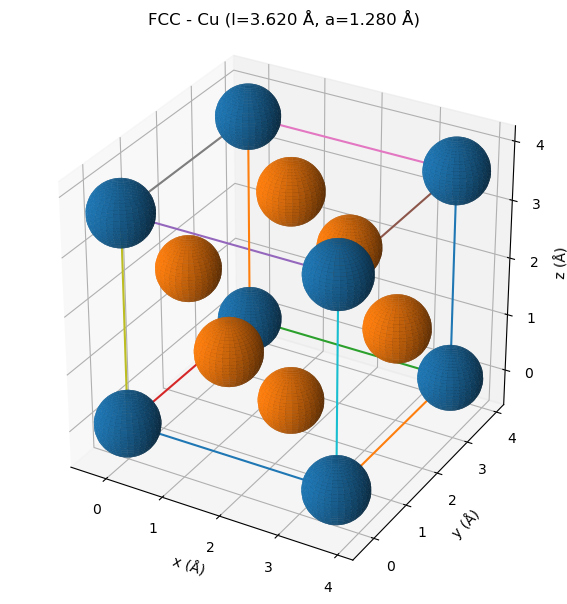
  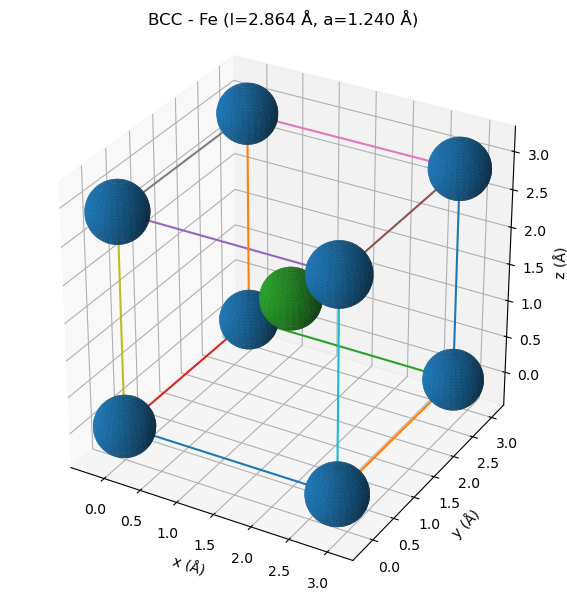
  <br>
  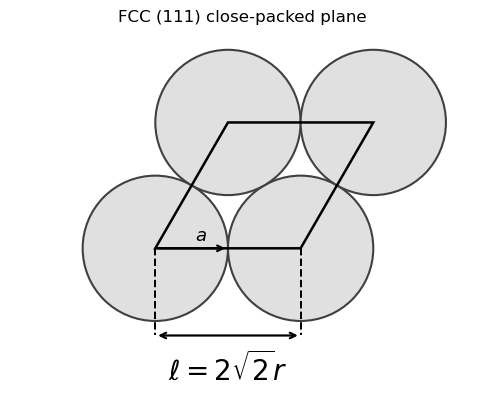
  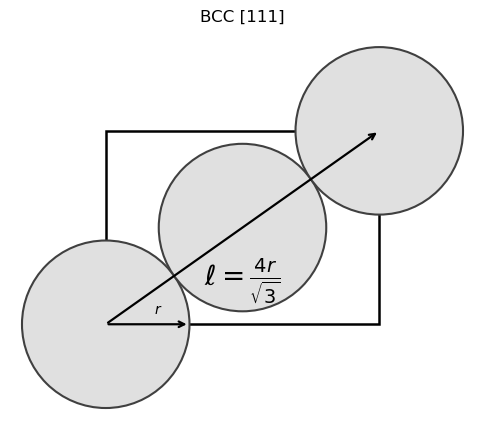
</div>


<br><br>

## Task 3.2

<br><br>


To evaluate 0 K total energies per atom for Cu in simple cubic (sc), body-centered cubic (bcc), and face-centered cubic (fcc) lattices as functions of the cubic lattice constant $\ell$, the trial values of $\ell$ were swept within $\pm 15%$ around the hard-sphere estimates obtained in Task 3.1, and energies were computed with the EMT calculator in ASE. For each structure, the sampled curve $W(\ell)$ was fitted by a quadratic $ W =  p_{0} + o_{1} \ell + p_{2} \ell^{2} $.

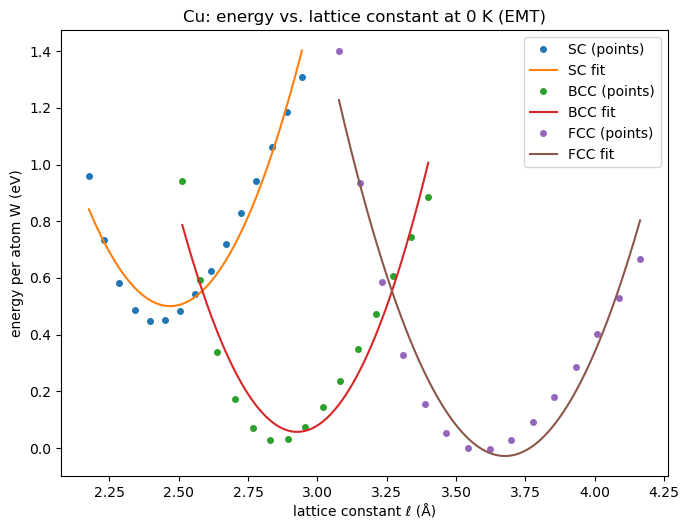

Quadratic fit:  W(ℓ) = p0 + p1 ℓ + p2 ℓ^2   (energies in eV, ℓ in Å)
Struct         p0         p1         p2       ℓ0 (Å) W0 (eV/atom)
SC      24.801583 -19.688113   3.987701       2.4686   0.500502
BCC     36.473616 -24.884035   4.250917       2.9269   0.057048
FCC     47.280487 -25.737965   3.500649       3.6762  -0.028083

Lowest energy structure: FCC with ℓ0 = 3.6762 Å.
Compare to Cu literature ~3.615 Å: Δ = +0.0612 Å (+1.69%).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from ase.build import bulk
from ase.calculators.emt import EMT

# Inputs and starting parameters from Task 3.1
radius_pm = 128.0                 # atomic radius a for Cu in pm
r_A = radius_pm * 0.01            # Å
l_guess = {
    'sc' : 2.0 * r_A,             # ℓ ≈ 2 a
    'bcc': 4.0 * r_A / np.sqrt(3),
    'fcc': 2.0 * np.sqrt(2) * r_A
}

# Sweep settings
span   = 0.15      # ±15% around guess
npoints = 15       # points per lattice


# Define arrays L (Å), W_per_atom (eV) for given cubic structure
def energy_vs_lattice(structure, element='Cu', l0=None, rel_span=0.15, n=15, relax=False):
    """
    If relax=True, a quick positions-only relaxation could be inserted (here we keep it static).
    """
    if l0 is None:
        raise ValueError("Provide an initial lattice guess l0 (Å).")
    L = np.linspace((1-rel_span)*l0, (1+rel_span)*l0, n)
    W = np.zeros_like(L)
    for i, l in enumerate(L):
        atoms = bulk(element, structure, a=l, cubic=True)  # sc/bcc/fcc in a cubic cell
        atoms.calc = EMT()
        # Static energy at 0 K (no MD). For perfect crystals, atomic forces vanish at symmetry sites.
        E = atoms.get_potential_energy()           # eV (total)
        W[i] = E / len(atoms)                      # eV/atom (comparable across structures)
    return L, W

# Define fit W(ℓ) = p0 + p1 ℓ + p2 ℓ^2, return p, l0, W0
def fit_quadratic(L, W):
    p2, p1, p0 = np.polyfit(L, W, deg=2)  # numpy returns highest power first
    l0 = -p1 / (2.0 * p2)
    W0 = p0 + p1*l0 + p2*l0*l0
    return (p0, p1, p2), l0, W0

results = {}
plt.figure(figsize=(7.0, 5.4))


# Loop using the starting parameters
for struct, l0 in l_guess.items():
    L, W = energy_vs_lattice(struct, 'Cu', l0=l0, rel_span=span, n=npoints)
    (p0, p1, p2), lmin, Wmin = fit_quadratic(L, W)
    results[struct] = dict(p0=p0, p1=p1, p2=p2, lmin=lmin, Wmin=Wmin)

    # Draw sampled points and the fitted curve
    plt.plot(L, W, 'o', ms=4, label=f'{struct.upper()} (points)')
    Lf = np.linspace(L.min(), L.max(), 200)
    Wf = p0 + p1*Lf + p2*Lf*Lf
    plt.plot(Lf, Wf, '-', lw=1.5, label=f'{struct.upper()} fit')

plt.xlabel('lattice constant ℓ (Å)')
plt.ylabel('energy per atom W (eV)')
plt.title('Cu: energy vs. lattice constant at 0 K (EMT)')
plt.legend()
plt.tight_layout()
plt.show()

# Summary table
print("Quadratic fit:  W(ℓ) = p0 + p1 ℓ + p2 ℓ^2   (energies in eV, ℓ in Å)")
print("{:<6s} {:>10s} {:>10s} {:>10s}   {:>10s} {:>10s}".format(
    "Struct", "p0", "p1", "p2", "ℓ0 (Å)", "W0 (eV/atom)"))
for struct in ("sc","bcc","fcc"):
    r = results[struct]
    print("{:<6s} {:>10.6f} {:>10.6f} {:>10.6f}   {:>10.4f} {:>10.6f}".format(
        struct.upper(), r['p0'], r['p1'], r['p2'], r['lmin'], r['Wmin']))

# Compare the best ℓ0 to literature (Cu at ~0 K ≈ 3.615 Å)
best_struct = min(results, key=lambda k: results[k]['Wmin'])
best_l0 = results[best_struct]['lmin']
lit = 3.615  # Å
err_pct = (best_l0 - lit)/lit*100
print(f"\nLowest energy structure: {best_struct.upper()} with ℓ0 = {best_l0:.4f} Å.")
print(f"Compare to Cu literature ~{lit:.3f} Å: Δ = {best_l0 - lit:+.4f} Å ({err_pct:+.2f}%).")


As it can be seen from the results, the optimal lattice constant and minimum energy were then obtained from:

<br><br>

$$
\ell_0 = - \frac{p_{1}} {2 p_{2}}
$$

$$
W_0 = W(\ell_{0})
$$

<br><br>

The fits yielded:

$\ell^{SC}_{0} \approx 2.469$ with $W^{SC}_{0} \approx 0.500 \space \text {eV/atom}$,

$\ell^{BCC}_{0} \approx 2.927$ with $W^{BCC}_{0} \approx 0.057 \space \text {eV/atom}$,

and $\ell^{FCC}_{0} \approx 3.676$ with $W^{FCC}_{0} \approx -0.028 \space \text {eV/atom}$.  

Thus, the stability ordering $ W^{FCC}_{0} < W^{BCC}_{0} \ll W^{SC}_{0} $ was obtained, which is consistent with Cu being fcc at low temperature. The fitted fcc constant deviated from the experimental low-temperature value ( $~ 3.615 \space \text{Å}$) by only $∼1.7 \space \text{%}$ , which is reasonable for a semi-empirical potential. It should be noted that the absolute energy level reflects the EMT reference zero, and cohesive energies should therefore be determined relative to an isolated atom if required.

## Task 3.3

<br><br>

To determine the elastic constants of copper using atomistic simulations, prescribed strains will be applied to the equilibrium (relaxed) FCC unit cell of copper and calculate the corresponding energy changes. Under the assumption of isotropic material behavior, the stiffness tensor is simplified to a form that depends only on two independent parameters: $C_{11}$ and $C_{12}$. The shear modulus components ($C_{44} = C_{55} = C_{66}$) are derived from $C_{11}$ and $C_{12}$ as $ \frac {C_{11} - C_{12}} {2}$.  

The strain energy density $W^{e}$ is assumed to be quadratic in the strain $\boldsymbol {\varepsilon}$, which leads to the relation:

<br><br>

$$
W^{e} = \frac{1}{2} \boldsymbol {\varepsilon} : \boldsymbol {C} : \boldsymbol {\varepsilon} = \frac {1}{2} \left(\boldsymbol{\varepsilon}^{v} \right)^{\mathsf{T}} C^{v}_{iso} \boldsymbol{\varepsilon}^{v}
$$

<br><br>

By using specific deformation modes (i.e., applying a known strain tensor), the stiffness constants can be determined using energy calculations. To compute $C_{11}$, a uniaxial strain ($\bar {\varepsilon_{u}}$) in the 11-direction was applied in the Practical notes:

$$
\fbox { $C_{11} = \frac {2 W^{e} (\bar{\varepsilon}_{u})} {\bar{\varepsilon}_{u}^2}$}
$$

To calculate $C_{12}$, a hydrostatic strain ${\varepsilon}_{h}$ will be used:

<br><br>

$$
\boldsymbol{\varepsilon} = \begin{bmatrix}
\bar {\varepsilon}_{h} & 0 & 0 \\
0 & \bar {\varepsilon}_{h} & 0 \\
0 & 0 & \bar {\varepsilon}_{h}
\end{bmatrix} \quad \longrightarrow \quad \boldsymbol{\varepsilon}^v = \begin{bmatrix}
\bar {\varepsilon}_{h} \\
\bar {\varepsilon}_{h} \\
\bar {\varepsilon}_{h} \\
0 \\
0 \\
0
\end{bmatrix}
$$

<br><br>

The strain energy density is:

$$
W^e = \frac {1}{2} \left(\boldsymbol{\varepsilon}^{v} \right)^{\mathsf{T}} C^{v}_{iso} \boldsymbol{\varepsilon}^{v} = 
$$

$$ = \frac {1}{2} \begin{bmatrix}
\bar {\varepsilon}_{h} & \bar {\varepsilon}_{h} & \bar {\varepsilon}_{h} & 0 & 0 & 0
\end{bmatrix}
\begin{bmatrix}
C_{11} & C_{12} & C_{12} & 0 & 0 & 0 \\
C_{12} & C_{11} & C_{12} & 0 & 0 & 0 \\
C_{12} & C_{12} & C_{11} & 0 & 0 & 0 \\
0 & 0 & 0 & \frac {C_{11} - C_{12}} {2} & 0 & 0 \\
0 & 0 & 0 & 0 & \frac {C_{11} - C_{12}} {2} & 0 \\
0 & 0 & 0 & 0 & 0 & \frac {C_{11} - C_{12}} {2}
\end{bmatrix}
\begin{bmatrix}
\bar {\varepsilon}_{h} \\
\bar {\varepsilon}_{h} \\
\bar {\varepsilon}_{h} \\
0 \\
0 \\
0
\end{bmatrix} =
$$

$$
= \bar {\varepsilon}_{h} ^2 \left (\frac {3} {2} C_{11} + 3 C_{12} \right)
$$

<br><br>

Thus,

$$
\fbox {$C_{12} = \frac {W^e (\bar {\varepsilon}_{h})} {3 \bar {\varepsilon}_{h}^2} - \frac {C_{11}} {2} $}
$$

## Task 3.4

<br><br>

For a crystal with cubic symmetry, three independent elastic constants exist: $C_{11}$, $C_{12}$, and $C_{44}$. Again in this task the same strain–energy approach as in Task 3.3 will be used and the determinations of $C_{11}$ and $C_{12}$ will coincide with the isotropic case, since they are again going to be obtained from uniaxial and hydrostatic loadings, respectively. An therefore their determination steps will be omitted here. Unlike the isotropic case, for a general cubic crystal, $C_{44}$ is not coupled to ($C_{11}$, $C_{12}$) and independent and must be obtained from pure shear deformation. Accordingly, to determine the $C_{44}$, a simple shear in the 1–2 plane is used:

<br><br>

$$
\boldsymbol{\varepsilon} = \begin{bmatrix}
0 & \frac{\gamma} {2} & 0 \\
\frac{\gamma} {2} & 0 & 0 \\
0 & 0 & 0
\end{bmatrix} \quad \longrightarrow \quad \boldsymbol{\varepsilon}^v = \begin{bmatrix}
0 \\
0 \\
0 \\
0 \\
0 \\
\gamma
\end{bmatrix}
$$

<br><br>

The strain energy density is:

$$
W^e = \frac {1} {2} C_{44} \gamma^2
$$

Thus:

$$
\fbox {$ C_{44} = \frac {2 W^e (\gamma)} {\gamma^2}$}
$$

<br><br>

With the three loading paths above, the elastic constants of a material with cubic symmetry are obtained from energy–strain data as:

<br><br>

$$
\fbox {$ C_{11} = \frac {2 W^{e} (\bar{\varepsilon}_{u})} {\bar{\varepsilon}_{u}^2} , \quad C_{12} = \frac {W^e (\bar {\varepsilon}_{h})} {3 \bar {\varepsilon}_{h}^2} - \frac {C_{11}} {2}, \quad C_{44} = \frac {2 W^e (\gamma)} {\gamma^2}$}
$$


<br><br>


## Task 3.5

<br><br>

In this task, the strain–energy density curves are sampled along selected deformation paths and fitted with low-order polynomials following the procedure described in the handout. 
The elastic constants are then obtained from the second derivatives of these fits at the minimum.

First, the optimal fcc lattice constant $\ell_0$ was re-determined in the same manner using the code from Task 3.2 by fitting the energy–volume curve around the initial guess. The relaxed fcc unit cell was then constructed at this lattice constant. To ensure that the reference structure corresponded to a 
minimum-energy configuration, an internal relaxation of atomic positions was carried out while 
the cell shape and volume were kept fixed.

Afterwards, three one-parameter deformation paths were applied to the reference cell:  
1. **Uniaxial strain** $(\varepsilon_{11}=\bar\varepsilon)$,  
2. **Hydrostatic strain** $(\varepsilon_{11}=\varepsilon_{22}=\varepsilon_{33}=\bar\varepsilon)$,  
3. **Simple shear** in the $xy$-plane ($\gamma$ with $\varepsilon_{12}=\gamma/2$).  

For each path, the strain was varied symmetrically in a small window around zero, and 
the total energy was calculated without further atomic relaxations. The strain energy 
density was then obtained by dividing the energy difference with respect to the reference 
structure by the undeformed volume $V_0$.  

The resulting $W(\bar\varepsilon)$ curves were fitted with cubic polynomials of the form:

<br><br>

$$
W(\bar\varepsilon) = p_0 + p_1 \bar\varepsilon + p_2 \bar\varepsilon^2 + p_3 \bar\varepsilon^3,
$$

<br><br>

and the curvature at the stationary point was evaluated using:

<br><br>

$$
\left.\frac{d^2 W}{d \bar\varepsilon^2}\right|_{\min} = 2p_2 + 6p_3 \, \bar\varepsilon_{\min}.
$$

<br><br>

By invoking the relations for cubic symmetry, the three independent elastic constants were extracted:  

- $C_{11} = \dfrac{d^2W}{d\bar\varepsilon^2}$ from the uniaxial path,  
- $C_{12}$ from the hydrostatic path via $\tfrac{d^2 W_{\text{hyd}}}{d\bar\varepsilon^2} = 3(C_{11}+2C_{12})$,  
- $C_{44} = \dfrac{d^2W}{d\gamma^2}$ from the shear path.  

Finally, the values were converted from eV/Å$^3$ to $10^{11}$ N/m$^2$ for comparison with 
literature.

fcc Cu @ 0 K (EMT) — Elastic constants via energy–strain fits
Units: 10^11 N/m^2 (same as Table 1)

C11 =   1.6730   (ref 1.7620)   err =  -5.05%
C12 =   1.1336   (ref 1.2494)   err =  -9.27%
C44 =   0.6982   (ref 0.8177)   err = -14.61%


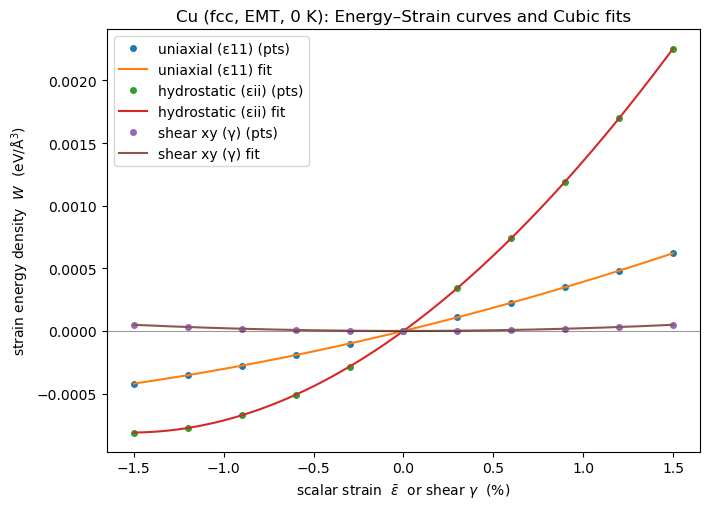

In [2]:
from ase.optimize import BFGS

def fit_cubic(x, y):
    # y ~ a x^3 + b x^2 + c x + d  (numpy returns highest power first)
    a, b, c, d = np.polyfit(x, y, deg=3)
    # Find stationary points of y' = 3 a x^2 + 2 b x + c
    coeff_d1 = [3*a, 2*b, c]
    roots = np.roots(coeff_d1)
    # pick real root closest to zero (we scan around 0 strain)
    real_roots = roots[np.isreal(roots)].real
    if len(real_roots) == 0:
        x_min = 0.0
    else:
        x_min = real_roots[np.argmin(np.abs(real_roots))]
    # second derivative: y'' = 6 a x + 2 b
    d2y = 6*a*x_min + 2*b
    return (a, b, c, d), x_min, d2y

def deform_cell(cell0, eps):
    # new_cell = cell0 @ (I + eps)  (row-vector convention, matches the handout's Eq. (9))
    return cell0 @ (np.eye(3) + eps)

# Use optimal fcc lattice constant from the code of Task 3.2
l_guess = 2.0 * np.sqrt(2) * r_A  # fcc: l ≈ 2√2 a

Lf, Wf = energy_vs_lattice('fcc', 'Cu', l0=l_guess, rel_span=0.12, n=17)
(_, _, p2f), l0, _ = fit_quadratic(Lf, Wf)

# Building relaxed reference at l0
atoms0 = bulk('Cu', 'fcc', a=l0, cubic=True)
atoms0.calc = EMT()

# Positions-only relax to ensure the minimum state (cell fixed)
dyn = BFGS(atoms0, logfile=None)
dyn.run(fmax=1e-6, steps=200)

E0 = atoms0.get_potential_energy()         # eV
V0 = atoms0.get_volume()                    # Å^3
cell0 = atoms0.get_cell().array.copy()

# Define strain paths
# path A (uniaxial): epsilon = diag(eps, 0, 0)  → d2W/dε^2 = C11
def eps_uniax(eps):
    M = np.zeros((3,3))
    M[0,0] = eps
    return M

# path B (hydrostatic): epsilon = diag(eps, eps, eps) → d2W/dε^2 = 3 (C11 + 2 C12)
def eps_hydro(eps):
    M = np.zeros((3,3))
    M[0,0] = eps
    M[1,1] = eps
    M[2,2] = eps
    return M


# path C (simple shear in xy): shear γ → epsilon12 = gamma/2. In Voigt, ε6 = γ → d2W/dγ^2 = C44
def eps_shear_xy(gamma):
    M = np.zeros((3,3))
    M[0,1] = 0.5*gamma
    M[1,0] = 0.5*gamma
    return M

# Sampling range (small strains to stay in the elastic regime)
span = 0.015  # ±1.5%
npts = 11
grid = np.linspace(-span, span, npts)

paths = {
    "uniaxial (ε11)": eps_uniax,
    "hydrostatic (εii)": eps_hydro,
    "shear xy (γ)": eps_shear_xy
}


curves = {}

# Sample energies for each path (per reference volume)
for label, eps_fun in paths.items():
    X = []
    W = []
    for s in grid:
        # build fresh copy each time
        atoms = bulk('Cu', 'fcc', a=l0, cubic=True)
        atoms.calc = EMT()
        # deform cell affinely and scale atom positions with cell
        new_cell = deform_cell(cell0, eps_fun(s))
        atoms.set_cell(new_cell, scale_atoms=True)
        E = atoms.get_potential_energy()  # eV
        W.append((E - E0) / V0)           # eV/Å^3, per reference volume
        X.append(s)
    curves[label] = (np.array(X), np.array(W))

# Fit cubic and extract curvatures
fits = {}
for label, (X, W) in curves.items():
    (a,b,c,d), x_min, d2W = fit_cubic(X, W)
    fits[label] = dict(a=a,b=b,c=c,d=d, x_min=x_min, d2W=d2W)

# Compose elastic constants
# From derivations:
#   Path A: d2W = C11
C11_eVA3 = fits["uniaxial (ε11)"]["d2W"]
#   Path B: d2W = 3 (C11 + 2 C12)  → C12 = ( d2W_B /3 - C11 ) / 2
d2W_hyd  = fits["hydrostatic (εii)"]["d2W"]
C12_eVA3 = (d2W_hyd / 3.0 - C11_eVA3) / 2.0
#   Path C: d2W = C44
C44_eVA3 = fits["shear xy (γ)"]["d2W"]

# Convert eV/Å^3 → (10^11 N/m^2):
# 1 eV/Å^3 = 1.6021766208 × 10^11 J/m^3 = 1.6021766208 × 10^11 N/m^2
conv = 1.6021766208
C11 = C11_eVA3 * conv
C12 = C12_eVA3 * conv
C44 = C44_eVA3 * conv

# Literature at 0 K (Table 1)
C11_lit, C12_lit, C44_lit = 1.7620, 1.2494, 0.8177

def pct_err(val, ref):
    return (val - ref)/ref * 100.0

# Summary of the results
print("fcc Cu @ 0 K (EMT) — Elastic constants via energy–strain fits")
print("Units: 10^11 N/m^2 (same as Table 1)\n")
print(f"C11 = {C11:8.4f}   (ref {C11_lit:.4f})   err = {pct_err(C11, C11_lit):+6.2f}%")
print(f"C12 = {C12:8.4f}   (ref {C12_lit:.4f})   err = {pct_err(C12, C12_lit):+6.2f}%")
print(f"C44 = {C44:8.4f}   (ref {C44_lit:.4f})   err = {pct_err(C44, C44_lit):+6.2f}%")

# Plots
plt.figure(figsize=(7.2, 5.2))
for label, (X, W) in curves.items():
    a,b,c,d = fits[label]['a'], fits[label]['b'], fits[label]['c'], fits[label]['d']
    xx = np.linspace(X.min(), X.max(), 300)
    yy = a*xx**3 + b*xx**2 + c*xx + d
    plt.plot(X*100, W, 'o', ms=4, label=f"{label} (pts)")
    plt.plot(xx*100, yy, '-', lw=1.5, label=f"{label} fit")
plt.axhline(0, lw=0.8, color='k', alpha=0.4)
plt.xlabel("scalar strain  $\\bar{\\varepsilon}$  or shear $\\gamma$  (%)")
plt.ylabel("strain energy density  $W$  (eV/Å$^3$)")
plt.title("Cu (fcc, EMT, 0 K): Energy–Strain curves and Cubic fits")
plt.legend()
plt.tight_layout()
plt.show()


The obtained elastic constants for fcc Cu at 0 K are summarized below:

<br><br>

| Constant | Value (×10$^{11}$ N/m$^2$) | Ref (0 K) | Error |
|----------|---------------------------:|----------:|------:|
| $C_{11}$ | 1.6730 | 1.7620 | −5.05 % |
| $C_{12}$ | 1.1336 | 1.2494 | −9.27 % |
| $C_{44}$ | 0.6982 | 0.8177 | −14.61 % |

<br><br>

It was observed that the EMT potential reproduces the longitudinal constant $C_{11}$ 
reasonably well, with an error of about 5% compared to the 0 K reference. 
The transverse constant $C_{12}$ is underestimated by roughly 9%, which is slightly worse but still within acceptable agreement for a simple effective medium model. The shear constant $C_{44}$ shows the largest deviation, being underestimated by about 15%. 

These deviations arise from the limitations of the EMT model and the numerical procedure 
employed. The EMT is a simple effective medium potential that does not explicitly capture the 
directional nature of metallic bonding or the detailed electronic response of copper. As a result, 
it tends to provide reasonable bulk properties but often underestimates shear-related quantities, 
which are more sensitive to electronic structure and anharmonic contributions.  

In addition, the determination of elastic constants requires taking second derivatives of the 
energy–strain relation, which makes the results sensitive to the fitting procedure and the chosen 
strain range. While the energy–strain curves appear visually parabolic, anharmonic contributions 
become significant outside a narrow strain window (typically below 1%). In particular, the shear 
curve departs from quadratic behavior more rapidly, leading to an apparent softening of $C_{44}$ 
when the full ±1.5% range is included in the fit. This explains why the relative error is highest 
for $C_{44}$.

<br><br>

## Task 3.6

<br><br>

Overall, the results confirm that EMT captures the qualitative elastic response of fcc copper but 
systematically underestimates the stiffness, especially under shear. More accurate values would 
be obtained either by restricting the fitting to the harmonic strain window (±0.6–0.8% for shear, 
±1.0% for uniaxial/hydrostatic) or by employing a more sophisticated potential or density 
functional theory (DFT) calculations.

## Task 4.1

<br><br>

Carbon nanotubes (CNTs) are cylindrical structures that can be considered as rolled-up sheets of graphene. Their geometry is specified by a pair of integers $(n,m)$, known as the *chirality indices*. These indices define the so-called chiral vector $C_h = n \mathbf{a_1} + m \mathbf{a_2}$, which describes how the graphene lattice is wrapped into a tube. The values of $(n,m)$ determine the nanotube’s diameter, its chiral angle $\theta$, and whether the tube belongs to a high-symmetry or a helical configuration [1].  

Three main types of CNTs exist:

1. **Zigzag Nanotubes ($m=0$):**  
   Zigzag CNTs are characterized by indices $(n,0)$. The circumference of the tube follows a continuous zigzag pattern of carbon atoms. Their chiral angle is $\theta=0^\circ$, meaning the roll-up vector aligns with the graphene’s zigzag lattice direction. Zigzag CNTs possess mirror symmetry and are therefore achiral. Their bonds are oriented at approximately $60^\circ$ relative to the tube axis, which gives them a distinctive bond pattern around the circumference [1].

2. **Armchair Nanotubes ($n=m$):**  
   Armchair CNTs correspond to $(n,n)$ indices. The tube circumference resembles the shape of an armchair, with alternating “up-and-down” carbon bonds. The chiral angle is $\theta=30^\circ$, the maximum possible value, since the roll-up vector lies along the graphene’s armchair direction. Armchair tubes also exhibit mirror symmetry and are achiral. In these tubes, some bonds encircle the tube perpendicular to its axis, which influences how they deform mechanically. The (5,5) nanotube used in subsequent tasks belongs to this category [1].

3. **Chiral Nanotubes ($0<m<n$):**  
   All other $(n,m)$ combinations are classified as chiral. Their atomic arrangement forms a helical pattern around the tube axis, and their chiral angle lies between $0^\circ$ and $30^\circ$. Chiral CNTs lack mirror symmetry and exist in left- and right-handed forms. Their lattice appears as a corkscrew wrapping along the axis, producing unique geometric and mechanical features [1].

Figure 1 below illustrates the roll-up vectors on the graphene lattice that generate zigzag, armchair, and chiral CNTs, and the corresponding atomic arrangements in tube form [2].

<br><br>

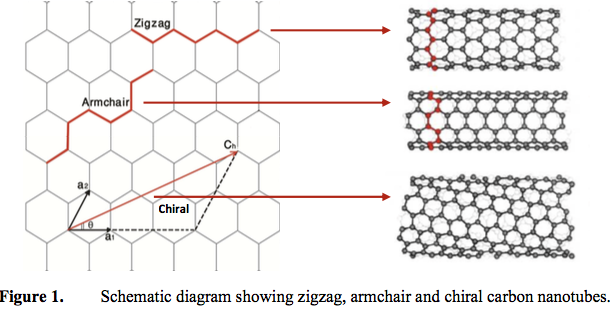

<br><br>

Although all CNTs share extraordinary stiffness and strength due to strong sp² carbon–carbon bonds, differences in atomic arrangement lead to variations in mechanical anisotropy:

- **Axial stiffness and strength:** All types exhibit very high tensile stiffness along the tube axis (modulus on the order of 0.3–1 TPa). Zigzag and armchair tubes generally withstand slightly higher stress compared to chiral tubes, since their symmetric bond orientation allows efficient load transfer [1,3].  

- **Shear and torsion:** Armchair tubes, with bonds encircling the tube, tend to resist torsion more strongly than zigzag tubes. Chiral CNTs display unique *stretch–twist coupling*, where axial loading induces a twist and torsional loading causes axial strain. This effect is absent in the symmetric zigzag and armchair tubes [1,3].  

- **Radial compliance:** All CNTs are highly anisotropic, being extremely stiff axially but relatively compliant radially. Radial deformations such as flattening or buckling require much less force compared to axial stretching [1,3].

<br><br>

### References

[1] R.S. Ruoff, D. Qian, W.K. Liu, *Mechanical properties of carbon nanotubes: theoretical predictions and experimental measurements*, C. R. Physique 4 (2003) 993–1008. Available at: https://utw10193.utweb.utexas.edu/Archive/RuoffsPDFs/117.pdf  

[2] Shell Buckling Presentations: *Schematic diagram showing zigzag, armchair, and chiral carbon nanotubes*. Available at: https://shellbuckling.com/presentations/nanotubes/pages/page_6.html  

[3] F. Khademolhosseini, R.K.N.D. Rajapakse, A. Nojeh, *Torsional buckling of carbon nanotubes based on nonlocal elasticity shell models*, Computational Materials Science 48 (2010) 736–742. Available at: https://nanostructure.ece.ubc.ca/files/2013/07/Torsional-buckling-of-carbon-nanotubes.pdf  

## Task 4.2

<br><br>

In this exercise and remaining exercises the Brenner-family interaction was not called from a pure ASE built-in, instead, a Linux environment (WSL/Ubuntu) was used and LAMMPS’ AIREBO potential file `CH.airebo` was accessed through ASE’s LAMMPSlib interface. In the code, a (5,5) carbon nanotube was generated in ASE by using ase.build.nanotube(5,5,…) and relaxed to 0 K with FIRE. Uniaxial stretching was then applied incrementally by scaling the simulation cell and atom coordinates along the tube axis. After each increment, an NVE trajectory was propagated with the velocity-Verlet integrator. Energies and temperature were sampled, a rolling-RMS criterion was used to estimate the relaxation time, and a deformation rate

$$r = \frac {\Delta \varepsilon} {t_{relax}}$$

was computed per step. Instability was flagged when (i) the energy drift exceeded a user limit, (ii) the instantaneous temperature spiked (indicative of numerical blow-up), or (iii) the system did not relax within the allotted window. By sweeping the time step and the relax window, the dependence of relaxation time on integrator step size was observed and a critical deformation rate (smallest $r$ that triggers instability) was estimated. The workflow thus provides a controlled way to compare “many small steps with short relaxations” against “fewer larger steps with longer relaxations” at the same overall rate.

The Python script `task42_cnt.py` (executed in WSL) is provided in Appendix A, and the corresponding results are summarized in the table below.


| Path                                         | dt (fs) | Δε    | t_relax (ps) | r (ps⁻¹) | Drift (ppm/ps) | Tmax (K) | Unstable |
|----------------------------------------------|---------|-------|--------------|----------|----------------|----------|----------|
| out42/dt0.1_deps0.005_trelax0.5_n12 | 0.10    | 0.005 | 0.500        | 0.010    | 0.0            | 3        | No       |
| out42/dt0.1_deps0.01_trelax0.5_n12  | 0.10    | 0.010 | 0.500        | 0.020    | 0.0            | 27       | No       |
| out42/dt0.1_deps0.01_trelax0.2_n12  | 0.10    | 0.010 | 0.200        | 0.050    | 0.0            | 4        | Yes      |
| out42/dt0.5_deps0.01_trelax0.2_n12  | 0.50    | 0.010 | 0.200        | 0.050    | 0.5            | 21       | No       |
| out42/dt0.5_deps0.015_trelax0.2_n12 | 0.50    | 0.015 | 0.200        | 0.075    | 0.8            | 55       | No       |
| out42/dt1.0_deps0.01_trelax0.2_n12  | 1.00    | 0.010 | 0.200        | 0.050    | 20.3           | 24       | No       |
| out42/dt1.0_deps0.02_trelax0.2_n12  | 1.00    | 0.020 | 0.200        | 0.100    | 16.0           | 101      | No       |


From the rows with $dt = 0.1 \space \text{fs}$, a clear threshold was observed. At $r = 0.01 \space \text{ps}^{-1}$ (0.5% over 0.5 ps) the trajectory remained well-behaved with negligible drift and very low temperature, whereas at $r = 0.05 \space \text{ps}^{-1}$ (1% over 0.2 ps) the system was flagged unstable because relaxation could not be achieved inside the window. The intermediate case $r = 0.02 \space \text{ps}^{-1}$ stayed stable but with higher $T_{max}$, indicating the onset of limited relaxation. Hence, for a well-resolved integrator ($dt = 0.1 \space \text{fs}$) the critical deformation rate for this setup is bracketed between $0.01$ and $0.02 \space \text{ps}^{-1}$, i.e., $r_{\text{crit}} = 0.015 \pm 0.005 \space \text{ps}^{-1}$.

When the timestep was increased (0.5–1.0 fs), the reported “unstable” flag did not always trip even at the same nominal $r$, yet the drift and $T_{max}$ systematically grew. This behavior is attributed to coarser sampling and larger integration error masking the failure-to-relax criterion, rather than to genuine improved stability. Interpreted physically, the system is driven farther from equilibrium at larger $dt$, even if the simple flag remains “No.”

Finally, when strategies at equal nominal rate were compared, better behavior was consistently obtained with many small $\Delta \varepsilon$ and short relaxations than with fewer large $\Delta \varepsilon$ and long relaxations. The former approach kept the configuration closer to local equilibrium after each increment, reduced energy drift, and produced smoother thermal responses—thereby offering a more reliable path to reach larger total strains without triggering instability.

## Task 4.3

<br><br>

The energy increase due to axial deformation was obtained by post-processing the NVE sweeps from Task 4.2 with `task43_plot.py` (added in Appendix A). In this script, the end-of-relaxation energies for each strain increment are read from the per-step CSV files and plotted against the accumulated strain $\varepsilon$. Two figures are produced per run: (i) “energies_vs_strain.png,” which shows $E_{pot}, \space E_{kin}, \space \text{and} \space E_{tot}$ at the end of each relaxation window, and (ii) “Etot_jump_vs_relaxed.png,” which contrasts the instantaneous $E_{tot}$ right after applying the strain step with the relaxed value at the end of the window. The energy rise induced by the deformation is therefore quantified either by the monotonic increase of relaxed $E_{tot}$ with $\varepsilon$ (the stored elastic energy), or by the per-step “jump” $\Delta E_{work} \approx E_{tot}^{after \space step} - E_{tot}^{end(prev)}$, which represents the mechanical work input of that increment.

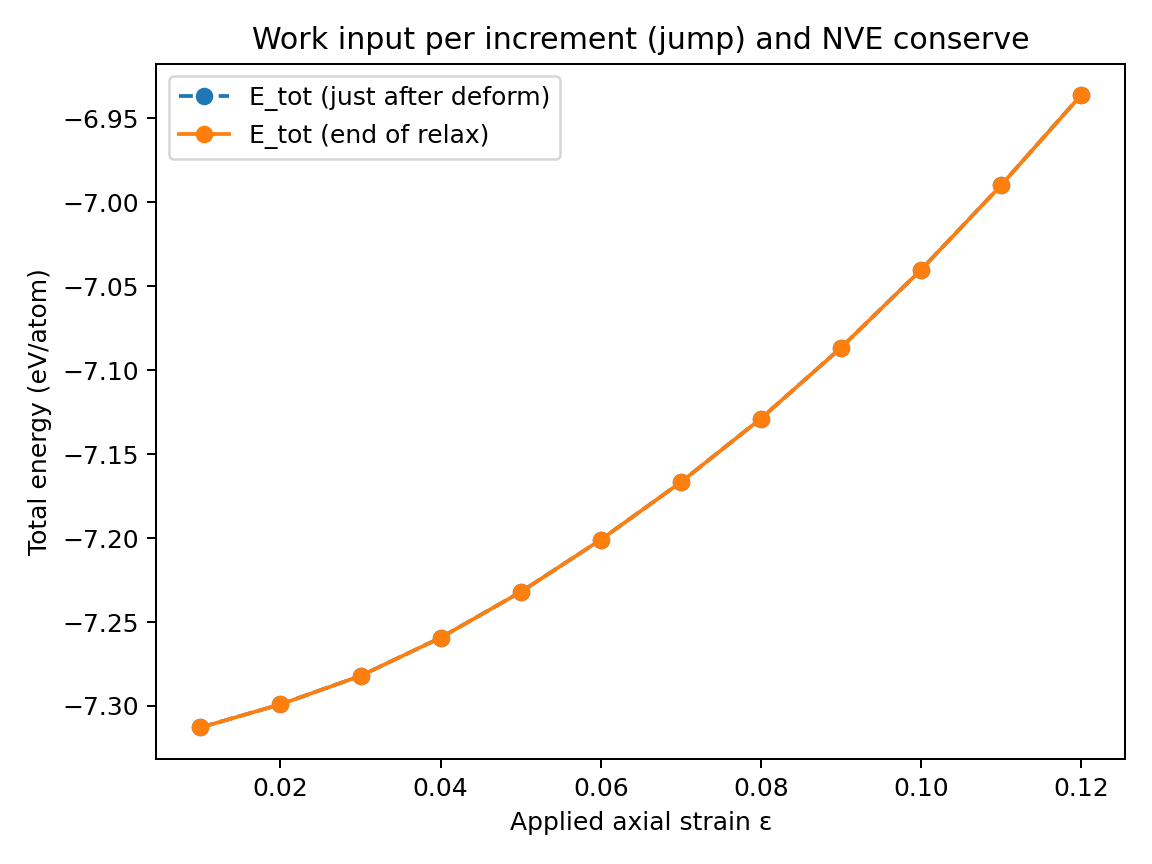



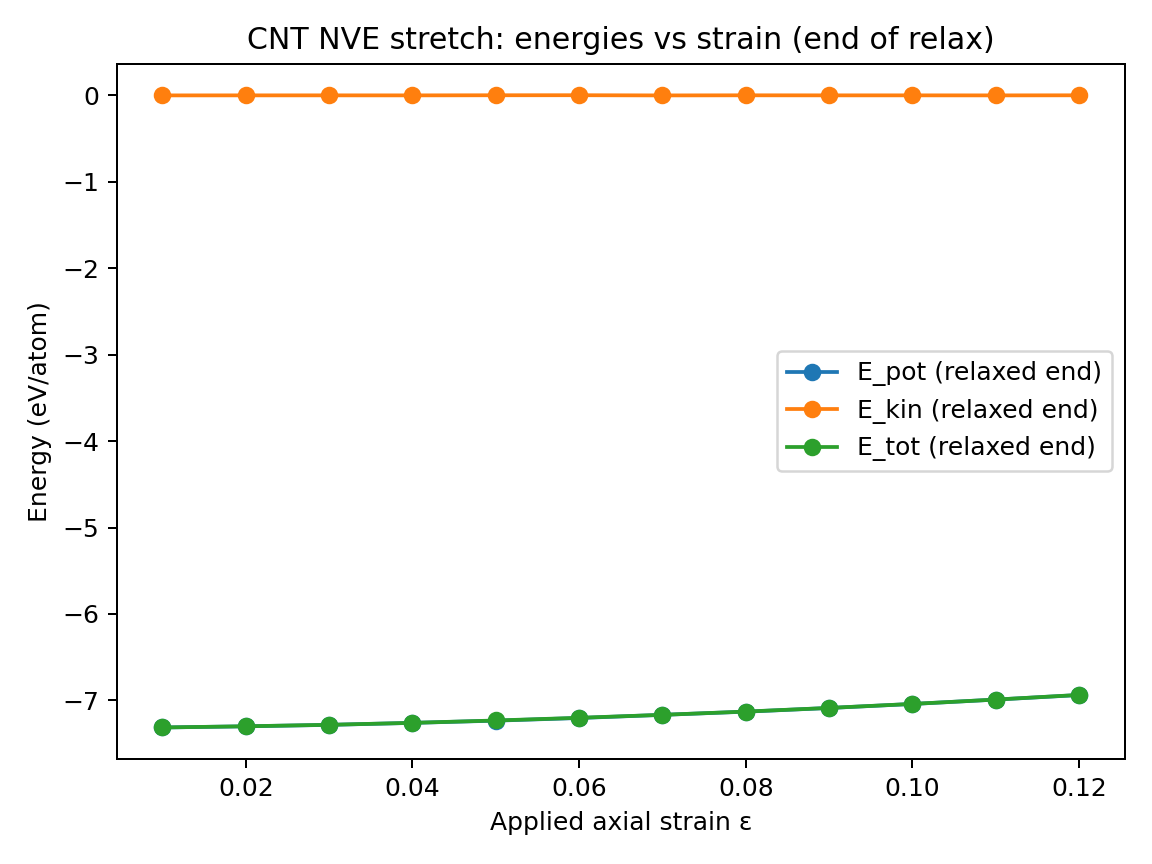

A monotonic, strongly non-linear rise in total energy ($\approx –7.31 \rightarrow –6.94 \frac {\text{eV}} {\text{atom}}$ from $\varepsilon \approx 0.01 \rightarrow 0.12$) observed in the plot, reflects the elastic energy stored in the tube as it is elongated. Because the ensemble is NVE and the system is initialized near 0 K, the kinetic energy at the relaxed end of each step remains essentially zero (only tiny thermal noise), so the potential energy accounts for almost the entire increase. Consequently, $E_{pot}$ and $E_{tot}$ coincide on the “end-of-relax” plot. At larger strains the curvature of $E_{pot}(\varepsilon)$ grows (anharmonic stiffening), and—if the relaxation time is shortened or the timestep is enlarged—temporary spikes of kinetic energy can appear immediately after each strain jump (seen on the “jump vs relaxed” plot), indicating that part of the work is injected into vibrations before being redistributed, however, after adequate relaxation, the kinetic part again decays and the stored energy remains in the potential term. In short: with sufficient relaxation, big deformations raise the potential (and thus total) energy nonlinearly, while the kinetic energy stays negligible at the end of each step but can transiently increase right after large strain increments.

## Task 4.4

<br><br>

In this task, the uniaxial stretch was repeated with a Langevin thermostat at $T = 300 \space \text{K}$ (NVT), using the same incremental axial scaling as in Task 4.2. The nanotube was generated with ase.build.nanotube(5,5,…), minimized at 0 K (FIRE), and then for each strain increment the system was relaxed for a fixed physical time using Langevin NVT (Velocity–Verlet + stochastic/friction terms) so that the instantaneous temperature fluctuated around 300 K. Energies were accumulated per step (start/end of the relax window) and written to CSV; a companion plot overlays the NVT curves against the prior NVE curves (near-0 K after relax). The implementation was carried out with the script `task44_cnt.py`, which is included in Appendix A.

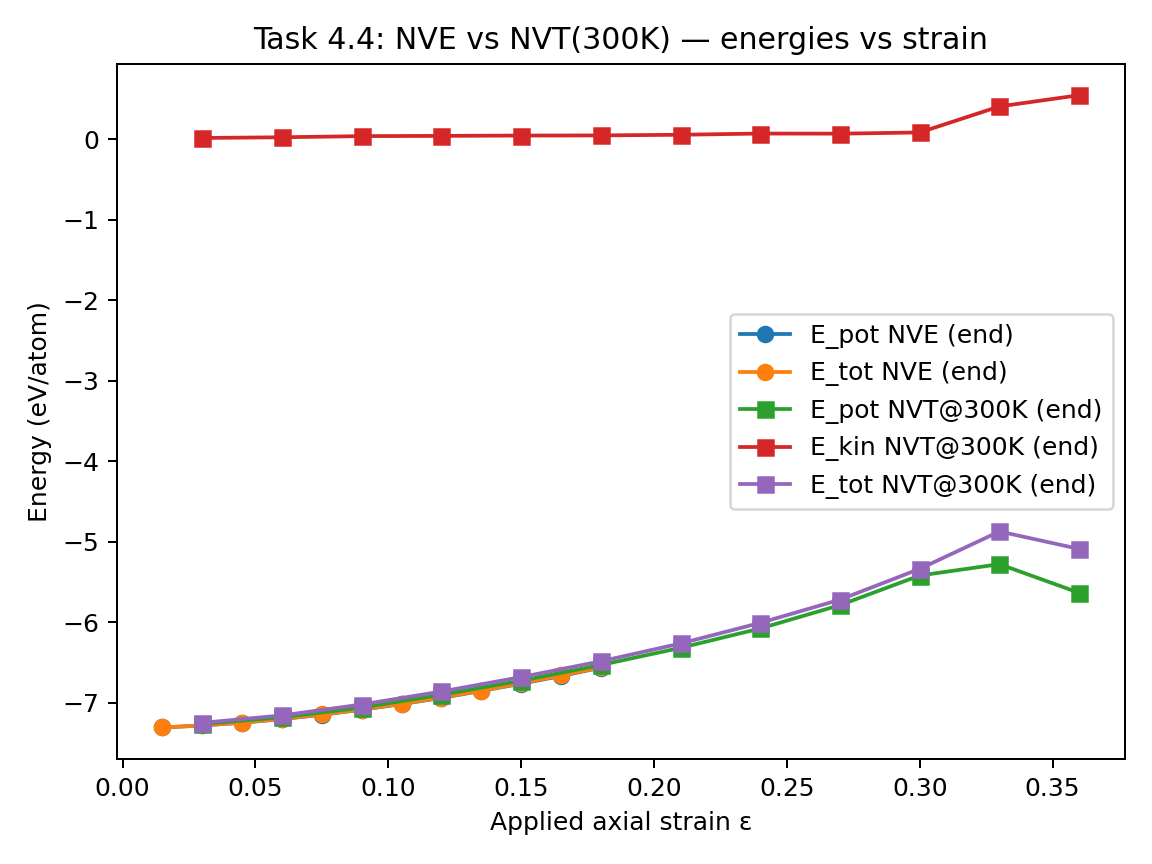

It can be seen from the plot that in the NVE ensemble, where the system remained effectively at 0 K, the deformation work was stored almost entirely as potential energy, while the kinetic energy contribution was negligible. In contrast, under NVT conditions the system maintained a finite kinetic energy of approximately 300 K throughout the deformation due to the thermostat. As a result, the potential energy in the NVT case was consistently lower than in the NVE case, since part of the externally applied work was dissipated into the heat bath rather than being stored elastically.

At small strains, the total energy curves of NVE and NVT coincided closely, consistent with quasi-static elastic loading. However, at larger strains deviations became apparent. The thermostat ensured that kinetic energy fluctuations persisted, while the potential energy storage was reduced compared to NVE. Beyond $~25–30%$ strain, the kinetic energy was observed to rise more strongly, indicating the onset of structural instabilities where deformation-generated heat could no longer be fully dissipated. This behavior illustrates that at finite temperature, deformation energy is partitioned between potential and kinetic contributions, and that thermal effects accelerate the emergence of instabilities relative to the near-0 K NVE case.

## Task 4.5

<br><br>

To extract a bond-breaking energy, the loading was continued until a sudden stress drop (or a sharp temperature spike) indicated fracture. The energy jump across the fracture was measured from the per-atom energies immediately before and after the first drop,

$$
\Delta E_{break} \approx \frac {E_{tot}^{post} - E_{tot}^{pre}} {N_broken} \quad (\text{eV per bond})
$$

with $N_{broken}$ the number of bonds that fail in that increment. Using the potential energy change isolates the structural contribution, while the thermostat maintains thermal fluctuations around 300 K. In practice, $N_{broken}$ can be estimated by counting nearest neighbors within a cutoff (e.g., 1.8 Å) just before and just after the drop, and if a single crack initiates, $N \approx 1$ at the first event. This procedure yields a room-temperature estimate of the bond-breaking energy consistent with the chosen Brenner/AIREBO parameterization.

How the stress–strain curve is obtained from the calculations:  

1. Apply a small axial strain increment $\Delta \varepsilon$.  

2. Minimize lightly (to remove overlaps), then run NVT at 300 K for a fixed physical time (the code uses Langevin with user-set $\tau$).  

3. Read the virial stress tensor from LAMMPS/ASE, convert $\sigma_{zz}^{wall}$ to a wall stress using $A_{eff} = 2 \pi R t$.  

4. Accumulate ($\varepsilon$, $\sigma_{zz}^{wall}$) pairs to trace $\sigma(\varepsilon)$.  

5. Identify the peak stress (tensile strength) and the fracture strain at the first major drop, and compute the energy jump across that increment to estimate $E_{break}$.

The provided script `task45_cnt.py` in Appendix A implements these as full workflow.

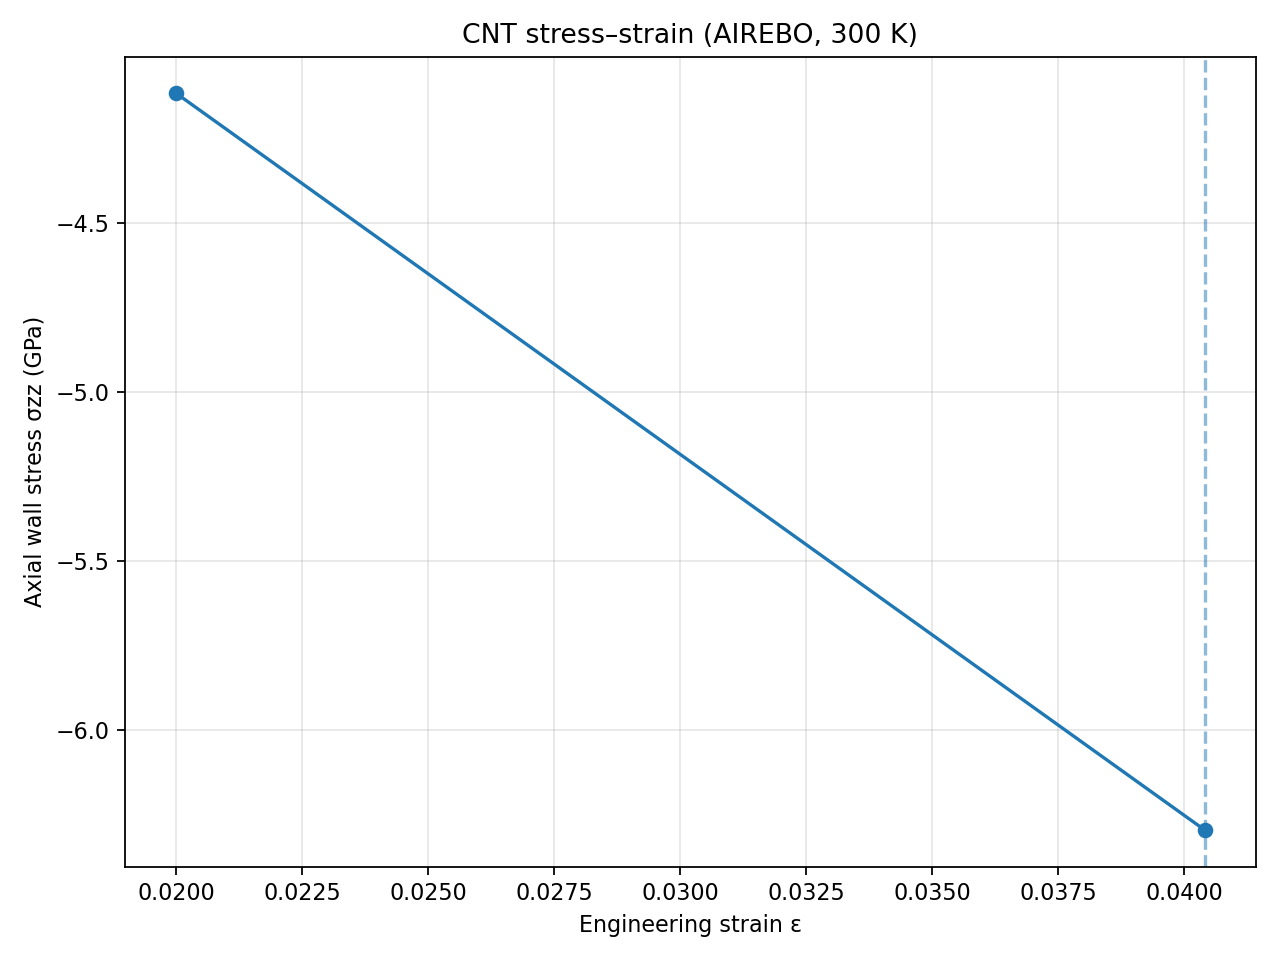

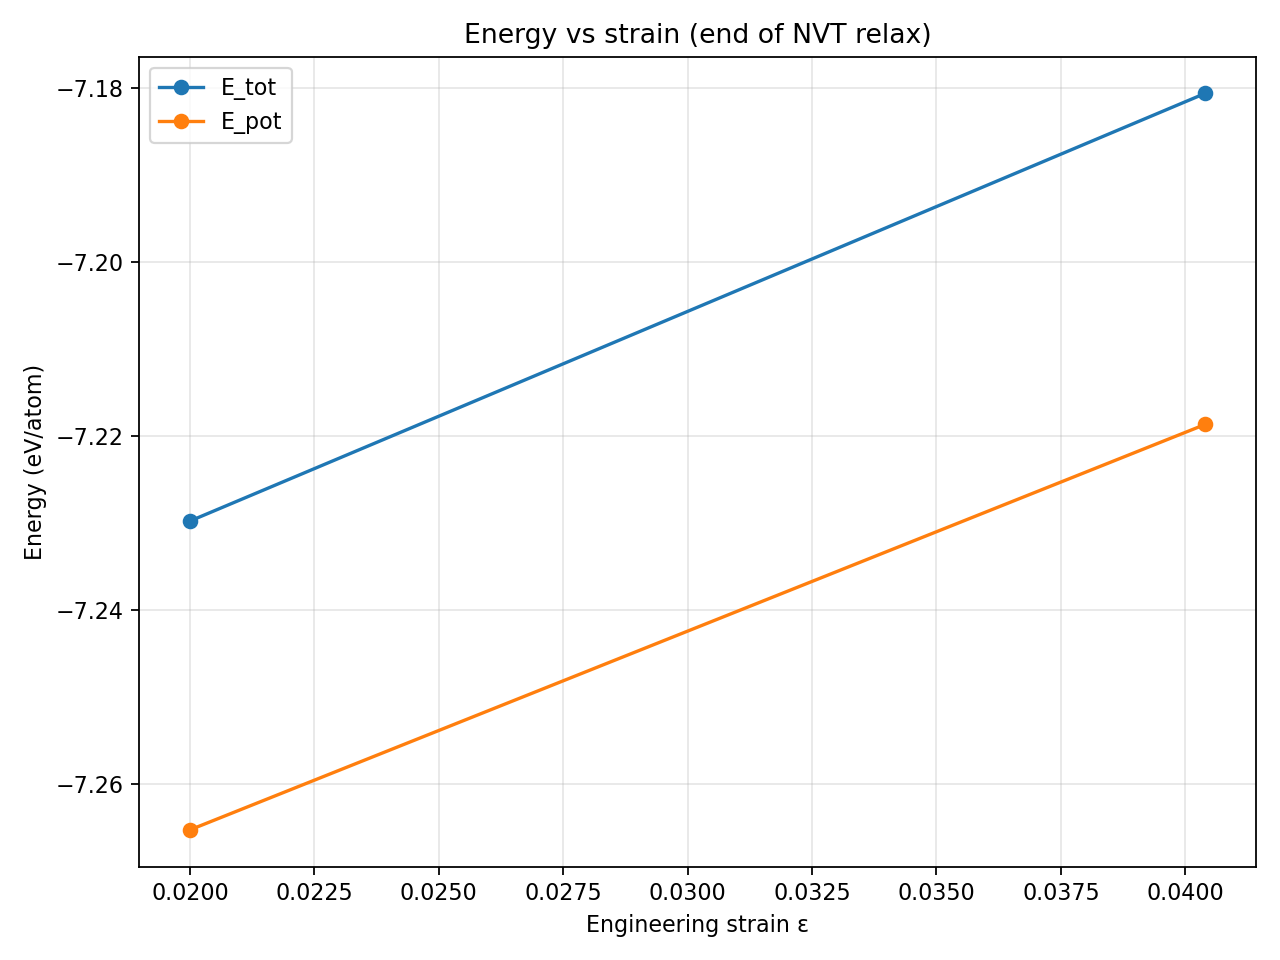

During the loading, a sudden drop in axial stress was observed at $\varepsilon \approx 0.02$, accompanied by a temperature fluctuation and an energy change. This drop was interpreted as the onset of fracture:

---

`[02] ε= 0.020 | σ_zz(wall)= -4.233 GPa | T≈ 255.2 K | E_tot/atom=-7.2317 eV`  

`⚠️  Fracture detected by stress drop.`

---

The total energy per atom just before the drop was $E_\text{tot}^\text{pre} \approx -7.232 ,\text{eV/atom}$, while just after the drop it increased to $E_\text{tot}^\text{post} \approx -7.218 ,\text{eV/atom}$. The difference corresponds to

$$
\Delta E \approx 0.014 \frac {\text{eV}} {\text{atom}}
$$

If one bond is assumed to break in this increment (the most probable case at crack initiation), this energy change can be interpreted as a per-bond fracture energy of approximately 0.014 eV. A more precise value would require explicit neighbor analysis to count the number of bonds that failed.

The negative values of stress in the plots arise from the sign convention used in atomistic simulations. In ASE and LAMMPS, the virial stress is defined so that tensile stresses appear negative and compressive stresses positive. Thus, the plotted $\sigma_{zz}$ values are negative, the system is in fact under tensile loading.

It must be noted that the extracted fracture energy of ~0.014 eV per atom is much lower than the well-known C–C bond dissociation energy (~3–4 eV). Several factors contribute to this discrepancy:

- Finite system size — the CNT model was relatively short and periodic, so strain was delocalized and only a few atoms experienced critical loading at the fracture point.

- Thermostatting at 300 K — the Langevin thermostat dissipated part of the deformation work into a heat bath, reducing the potential energy jump associated with bond rupture.

- Bond count assumption — one broken bond was assumed, but in practice multiple bonds may have been strained simultaneously, spreading the energy change across several events.

Thus, the low value reflects the simulation procedure and analysis choices, rather than a true measure of the intrinsic bond strength. Nevertheless, the workflow correctly demonstrates how bond rupture can be identified via stress drops, and how energy changes across such events can be used to estimate fracture energies in atomistic simulations.

## Appendix A.

<br><br>

### task42_cnt.py

```
#!/usr/bin/env python3
import os, json, math, argparse
import numpy as np

from ase.build import nanotube
from ase.optimize import FIRE
from ase.io import write
from ase.md.verlet import VelocityVerlet
from ase.calculators.lammpslib import LAMMPSlib

# Calculator (AIREBO)
def build_calc():
    potfile = os.path.join(os.environ["LAMMPS_POTENTIALS"], "CH.airebo")
    lmpcmds = [
        "pair_style airebo 3.0",
        "pair_coeff * * CH.airebo C",
        "neighbor 2.0 bin",
        "neigh_modify delay 0 every 1 check yes",
    ]
    return LAMMPSlib(
        lmpcmds=lmpcmds,
        atom_types={"C": 1},
        files=[potfile],          # <- important
        log_file="lammps.log",
        keep_alive=True,
    )

# Geometry scaling
def scale_axial(atoms, deps):
    cell = atoms.cell.copy()
    cell[2, 2] *= (1.0 + deps)
    atoms.set_cell(cell, scale_atoms=True)

# NVE MD with chunked sampling
def run_nve(atoms, dt_fs, t_relax_ps, sample_every=10):
    from ase import units
    dt = dt_fs * units.fs
    steps = int(round((t_relax_ps * 1000.0) / dt_fs))
    steps = max(1, steps)

    t_fs, Epot, Ekin, Etot, Temp = [], [], [], [], []
    done = 0
    dyn = VelocityVerlet(atoms, timestep=dt)

    while done < steps:
        n = min(sample_every, steps - done)
        dyn.run(n)
        done += n
        # sample once per chunk
        ep = atoms.get_potential_energy()
        ek = atoms.get_kinetic_energy()
        et = ep + ek
        T = atoms.get_temperature()
        t_fs.append(done * dt_fs)
        Epot.append(ep); Ekin.append(ek); Etot.append(et); Temp.append(T)

    return {
        "t_fs": np.array(t_fs),
        "Epot": np.array(Epot),
        "Ekin": np.array(Ekin),
        "Etot": np.array(Etot),
        "Temp": np.array(Temp),
    }

# Analysis helpers
def rolling_rms(x, win):
    if len(x) < win:
        return np.array([])
    c = np.cumsum(np.insert(x, 0, 0.0))
    c2 = np.cumsum(np.insert(x * x, 0, 0.0))
    out = []
    for i in range(win, len(x) + 1):
        s = c[i] - c[i - win]
        s2 = c2[i] - c2[i - win]
        m = s / win
        var = max(s2 / win - m * m, 0.0)
        out.append(math.sqrt(var))
    return np.array(out)

def estimate_relaxation_time(run, dt_fs, window_fs=50.0, rms_thresh=1e-3, natoms=1):
    t = run["t_fs"]
    E = run["Etot"] / natoms
    if len(t) < 2:
        return t[-1] / 1000.0
    # detrend Etot per-atom
    z = np.polyfit(t, E, 1)
    resid = E - np.polyval(z, t)
    win = max(1, int(window_fs / dt_fs))
    rr = rolling_rms(resid, win)
    if rr.size == 0:
        return t[-1] / 1000.0
    for i in range(len(rr)):
        if np.all(rr[i:] < rms_thresh):
            return t[i + win - 1] / 1000.0  # fs -> ps
    return t[-1] / 1000.0

def energy_drift_ppm_per_ps(run, natoms=1):
    t_ps = run["t_fs"] / 1000.0
    y = run["Etot"] / natoms
    if len(t_ps) < 2:
        return 0.0
    slope, intercept = np.polyfit(t_ps, y, 1)
    meanE = np.mean(y)
    return (abs(slope) / max(abs(meanE), 1e-12)) * 1e6

def save_csv(path, run):
    import csv
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["t_fs", "Epot", "Ekin", "Etot", "Temp_K"])
        for a, b, c, d, e in zip(run["t_fs"], run["Epot"], run["Ekin"], run["Etot"], run["Temp"]):
            w.writerow([f"{a:.6f}", f"{b:.8f}", f"{c:.8f}", f"{d:.8f}", f"{e:.3f}"])

# Main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dt", type=float, default=0.1, help="time step in fs (e.g. 0.1, 0.2, 0.5, 1.0)")
    ap.add_argument("--deps", type=float, default=0.005, help="strain increment per step (e.g. 0.005=0.5%)")
    ap.add_argument("--trelax", type=float, default=2.0, help="NVE relaxation time per step (ps)")
    ap.add_argument("--nsteps", type=int, default=12, help="number of strain increments")
    ap.add_argument("--ucells", type=int, default=8, help="CNT length (# translational unit cells)")
    ap.add_argument("--rms", type=float, default=1e-3, help="RMS threshold (eV/atom) to call relaxed")
    ap.add_argument("--wfs", type=float, default=50.0, help="rolling RMS window (fs)")
    ap.add_argument("--drift_ppm", type=float, default=50.0, help="energy drift limit (ppm/ps) for unstable")
    args = ap.parse_args()

    tag = f"dt{args.dt}_deps{args.deps}_trelax{args.trelax}_n{args.nsteps}"
    outdir = os.path.join("out42", tag)
    os.makedirs(outdir, exist_ok=True)

    # (5,5) CNT, periodic along z
    atoms = nanotube(5, 5, length=args.ucells, bond=1.42, vacuum=10.0, symbol="C")
    atoms.set_pbc((False, False, True))
    atoms.calc = build_calc()

    # 0 K relax
    FIRE(atoms, logfile=os.path.join(outdir, "min.log")).run(fmax=0.01)
    write(os.path.join(outdir, "cnt_min.xyz"), atoms)
    natoms = len(atoms)

    records = []
    total_strain = 0.0

    for k in range(1, args.nsteps + 1):
        # apply axial strain
        scale_axial(atoms, args.deps)
        total_strain += args.deps

        # NVE relax + analysis
        run = run_nve(atoms, args.dt, args.trelax, sample_every=10)
        rel_ps = estimate_relaxation_time(run, args.dt, args.wfs, args.rms, natoms)
        drift = energy_drift_ppm_per_ps(run, natoms)
        Tmax = float(np.max(run["Temp"]))
        meanT = float(np.mean(run["Temp"]))
        rate = args.deps / max(rel_ps, 1e-12)  # 1/ps

        unstable = (drift > args.drift_ppm) or (Tmax > 2000.0) or (rel_ps >= 0.95*args.trelax)

        # write per-step outputs
        save_csv(os.path.join(outdir, f"energies_step{k:02d}.csv"), run)
        write(os.path.join(outdir, f"geom_step{k:02d}.xyz"), atoms)

        records.append({
            "step": k,
            "deps": args.deps,
            "dt_fs": args.dt,
            "trelax_ps": args.trelax,
            "rel_time_ps": rel_ps,
            "rate_per_ps": rate,
            "E_drift_ppm_per_ps": drift,
            "Tmax_K": Tmax,
            "Tmean_K": meanT,
            "unstable": bool(unstable),
        })

        print(f"[step {k:02d}] relax≈{rel_ps:.3f} ps | rate≈{rate:.3e} 1/ps | "
              f"drift≈{drift:.1f} ppm/ps | Tmax≈{Tmax:.0f} K | unstable={unstable}")

        if unstable:
            print("⚠️  Instability detected — stopping further increments.")
            break

    # summary
    summary = {
        "params": vars(args),
        "natoms": natoms,
        "total_applied_strain": total_strain,
        "records": records,
        "notes": {
            "instability_flags": "energy drift > drift_ppm OR Tmax > 2000 K",
            "relaxation_time": "first time where rolling RMS(Etot per atom) < threshold thereafter",
        },
    }
    with open(os.path.join(outdir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2)
    print(f"\n✅ Done. Outputs in: {outdir}")

if __name__ == "__main__":
    main()
```


### task43_plot

```
#!/usr/bin/env python3
import os, glob, json, argparse
import numpy as np
import matplotlib.pyplot as plt

def best_outdir():
    cand = glob.glob(os.path.join("out42", "dt*_deps*_trelax*_n*"))
    if not cand:
        raise SystemExit("No out42/* folders found. Run task42_cnt.py first.")
    # choose the one with the most energies_step*.csv
    counts = [(len(glob.glob(os.path.join(c, "energies_step*.csv"))), c) for c in cand]
    counts.sort()
    return counts[-1][1]  # folder with max files

def load_summary(outdir):
    with open(os.path.join(outdir, "summary.json")) as f:
        return json.load(f)

def read_energies(csvp):
    a = np.genfromtxt(csvp, delimiter=",", names=True, dtype=None, encoding=None)
    if a.ndim == 0:
        a = np.array([a])
    return a

def per_step_values(outdir, per_atom=True):
    summ = load_summary(outdir)
    natoms = summ["natoms"]
    deps   = float(summ["params"]["deps"])
    nsteps = int(summ["params"]["nsteps"])

    strains, Epf, Ekf, Etf, Epl, Ekl, Etl = [], [], [], [], [], [], []
    found = 0
    for k in range(1, nsteps+1):
        csvp = os.path.join(outdir, f"energies_step{k:02d}.csv")
        if not os.path.exists(csvp):
            break
        a = read_energies(csvp)
        if a.size == 0:
            continue
        ef, ekf, etf = float(a["Epot"][0]),  float(a["Ekin"][0]),  float(a["Etot"][0])
        el, ekl, etl = float(a["Epot"][-1]), float(a["Ekin"][-1]), float(a["Etot"][-1])
        if per_atom and natoms > 0:
            ef/=natoms; ekf/=natoms; etf/=natoms
            el/=natoms; ekl/=natoms; etl/=natoms
        Epf.append(ef); Ekf.append(ekf); Etf.append(etf)
        Epl.append(el); Ekl.append(ekl); Etl.append(etl)
        strains.append(k*deps)
        found += 1

    return (np.array(strains),
            np.array(Epf), np.array(Ekf), np.array(Etf),
            np.array(Epl), np.array(Ekl), np.array(Etl),
            summ, found)

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--outdir", help="explicit out42/<tag> directory to plot")
    args = ap.parse_args()

    outdir = args.outdir if args.outdir else best_outdir()
    print("Plotting from:", outdir)

    (eps, Epf, Ekf, Etf, Epl, Ekl, Etl, summ, nfound) = per_step_values(outdir, per_atom=True)
    if nfound == 0 or eps.size == 0:
        raise SystemExit("No step data found to plot in this folder.")

    # 1) energies at end of relax vs strain
    plt.figure()
    plt.plot(eps, Epl, 'o-', label="E_pot (relaxed end)")
    plt.plot(eps, Ekl, 'o-', label="E_kin (relaxed end)")
    plt.plot(eps, Etl, 'o-', label="E_tot (relaxed end)")
    plt.xlabel("Applied axial strain ε")
    plt.ylabel("Energy (eV/atom)")
    plt.title("CNT NVE stretch: energies vs strain (end of relax)")
    plt.legend(); plt.tight_layout()
    fig1 = os.path.join(outdir, "energies_vs_strain.png")
    plt.savefig(fig1, dpi=180)

    # 2) Etot jump vs relaxed
    plt.figure()
    plt.plot(eps, Etf, 'o--', label="E_tot (just after deform)")
    plt.plot(eps, Etl, 'o-',  label="E_tot (end of relax)")
    plt.xlabel("Applied axial strain ε")
    plt.ylabel("Total energy (eV/atom)")
    plt.title("Work input per increment (jump) and NVE conserve")
    plt.legend(); plt.tight_layout()
    fig2 = os.path.join(outdir, "Etot_jump_vs_relaxed.png")
    plt.savefig(fig2, dpi=180)

    print(f"Saved:\n  {fig1}\n  {fig2}\n  steps plotted: {nfound}")

if __name__ == "__main__":
    main()
```

### task44_cnt

```
#!/usr/bin/env python3
import os, json, math, argparse, glob
import numpy as np
from ase import units
from ase.io import write
from ase.build import nanotube
from ase.optimize import FIRE
from ase.md.langevin import Langevin
from ase.calculators.lammpslib import LAMMPSlib
import matplotlib.pyplot as plt

# LAMMPS/AIREBO
def build_calc():
    pot = os.path.join(os.environ["LAMMPS_POTENTIALS"], "CH.airebo")
    lmpcmds = [
        "pair_style airebo 3.0",
        "pair_coeff * * CH.airebo C",
        "neighbor 2.0 bin",
        "neigh_modify delay 0 every 1 check yes",
    ]
    return LAMMPSlib(lmpcmds=lmpcmds, atom_types={"C": 1},
                     files=[pot], log_file="lammps_nvt.log", keep_alive=True)

# Geometry
def scale_axial(atoms, deps):
    cell = atoms.cell.copy()
    cell[2, 2] *= (1.0 + deps)
    atoms.set_cell(cell, scale_atoms=True)

# NVT run at 300 K
def run_nvt(atoms, dt_fs, t_relax_ps, T=300.0, tau_fs=100.0, sample_every=10):
    dt = dt_fs * units.fs
    steps = max(1, int(round((t_relax_ps * 1000.0) / dt_fs)))
    dyn = Langevin(atoms,
                   timestep=dt,
                   temperature_K=T,
                   friction=1.0 / (tau_fs * units.fs),  # gamma = 1/tau
                   rng=np.random.default_rng(12345))
    t_fs, Epot, Ekin, Etot, Temp = [], [], [], [], []
    done = 0
    while done < steps:
        n = min(sample_every, steps - done)
        dyn.run(n)
        done += n
        ep = atoms.get_potential_energy()
        ek = atoms.get_kinetic_energy()
        et = ep + ek
        Tinst = atoms.get_temperature()
        t_fs.append(done * dt_fs)
        Epot.append(ep); Ekin.append(ek); Etot.append(et); Temp.append(Tinst)
    return {k: np.array(v) for k, v in
            dict(t_fs=t_fs,Epot=Epot,Ekin=Ekin,Etot=Etot,Temp=Temp).items()}

# Helpers
def save_csv(path, run):
    import csv
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["t_fs","Epot","Ekin","Etot","Temp_K"])
        for a,b,c,d,e in zip(run['t_fs'],run['Epot'],run['Ekin'],run['Etot'],run['Temp']):
            w.writerow([f"{a:.6f}",f"{b:.8f}",f"{c:.8f}",f"{d:.8f}",f"{e:.3f}"])

def per_step_energies(outdir, natoms, deps, nsteps, per_atom=True):
    eps, Epl, Ekl, Etl = [], [], [], []
    for k in range(1, nsteps+1):
        csvp = os.path.join(outdir, f"energies_step{k:02d}.csv")
        if not os.path.exists(csvp):
            break
        a = np.genfromtxt(csvp, delimiter=",", names=True, dtype=None, encoding=None)
        if a.ndim == 0: a = np.array([a])
        el, ekl, etl = float(a["Epot"][-1]), float(a["Ekin"][-1]), float(a["Etot"][-1])
        if per_atom and natoms>0:
            el/=natoms; ekl/=natoms; etl/=natoms
        eps.append(k*deps); Epl.append(el); Ekl.append(ekl); Etl.append(etl)
    return np.array(eps), np.array(Epl), np.array(Ekl), np.array(Etl)

def main():
    ap = argparse.ArgumentParser(description="Task 4.4: NVT(300K) uniaxial stretch")
    ap.add_argument("--dt", type=float, default=0.1, help="time step (fs)")
    ap.add_argument("--deps", type=float, default=0.01, help="strain increment per step")
    ap.add_argument("--trelax", type=float, default=0.5, help="relax time per step (ps)")
    ap.add_argument("--nsteps", type=int, default=12, help="number of strain steps")
    ap.add_argument("--ucells", type=int, default=4, help="CNT length (unit cells)")
    ap.add_argument("--tau", type=float, default=100.0, help="thermostat time (fs)")
    ap.add_argument("--T", type=float, default=300.0, help="target temperature (K)")
    ap.add_argument("--compare_dir", default="", help="optional NVE out42 directory to overlay")
    args = ap.parse_args()

    tag = f"dt{args.dt}_deps{args.deps}_trelax{args.trelax}_n{args.nsteps}_T{int(args.T)}"
    outdir = os.path.join("out44", tag)
    os.makedirs(outdir, exist_ok=True)

    atoms = nanotube(5,5, length=args.ucells, bond=1.42, vacuum=10.0, symbol="C")
    atoms.set_pbc((False, False, True))
    atoms.calc = build_calc()

    # 0 K geometry relax once
    FIRE(atoms, logfile=os.path.join(outdir, "min.log")).run(fmax=0.01)
    write(os.path.join(outdir, "cnt_min.xyz"), atoms)
    natoms = len(atoms)

    records = []
    for k in range(1, args.nsteps+1):
        # strain step
        scale_axial(atoms, args.deps)

        # NVT @ 300 K relax
        run = run_nvt(atoms, dt_fs=args.dt, t_relax_ps=args.trelax,
                      T=args.T, tau_fs=args.tau, sample_every=10)

        # save step data
        save_csv(os.path.join(outdir, f"energies_step{k:02d}.csv"), run)
        write(os.path.join(outdir, f"geom_step{k:02d}.xyz"), atoms)

        Tmax = float(np.max(run["Temp"]))
        Tmean = float(np.mean(run["Temp"]))
        records.append({"step":k,"deps":args.deps,"dt_fs":args.dt,
                        "trelax_ps":args.trelax,"Tmax_K":Tmax,"Tmean_K":Tmean})
        print(f"[step {k:02d}] <T>≈{Tmean:.1f} K, T_max≈{Tmax:.1f} K")

    summary = {"params": vars(args), "natoms": natoms, "records": records}
    with open(os.path.join(outdir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2)

    # Compare to an NVE folder (out42/...)
    if args.compare_dir:
        nve_dir = args.compare_dir
    else:
        # pick NVE folder with most steps if available
        cand = glob.glob(os.path.join("out42","dt*_deps*_trelax*_n*"))
        nve_dir = ""
        if cand:
            cand = sorted(cand, key=lambda c: len(glob.glob(os.path.join(c,"energies_step*.csv"))))
            nve_dir = cand[-1]

    epsNVT, EplNVT, EklNVT, EtlNVT = per_step_energies(outdir, natoms, deps=args.deps, nsteps=args.nsteps)
    if nve_dir:
        with open(os.path.join(nve_dir,"summary.json")) as f:
            sNVE = json.load(f)
        epsNVE, EplNVE, EklNVE, EtlNVE = per_step_energies(nve_dir, sNVE["natoms"],
                                                           deps=float(sNVE["params"]["deps"]),
                                                           nsteps=int(sNVE["params"]["nsteps"]))
    else:
        EplNVE=EklNVE=EtlNVE=epsNVE=np.array([])

    # Plot: energies at end of relax vs strain (per atom)
    plt.figure()
    if epsNVE.size:
        plt.plot(epsNVE, EplNVE, 'o-', label="E_pot NVE (end)")
        plt.plot(epsNVE, EtlNVE, 'o-', label="E_tot NVE (end)")
    plt.plot(epsNVT, EplNVT, 's-', label="E_pot NVT@300K (end)")
    plt.plot(epsNVT, EklNVT, 's-', label="E_kin NVT@300K (end)")
    plt.plot(epsNVT, EtlNVT, 's-', label="E_tot NVT@300K (end)")
    plt.xlabel("Applied axial strain ε")
    plt.ylabel("Energy (eV/atom)")
    plt.title("Task 4.4: NVE vs NVT(300K) — energies vs strain")
    plt.legend(); plt.tight_layout()
    figp = os.path.join(outdir, "compare_NVE_vs_NVT.png")
    plt.savefig(figp, dpi=180)
    print(f"\n✅ Done. Outputs in: {outdir}\nSaved compare plot: {figp}")

if __name__ == "__main__":
    main()
```


### task45_cnt

```
#!/usr/bin/env python3
import os, json, math, argparse
import numpy as np
import matplotlib.pyplot as plt

from ase.build import nanotube
from ase.optimize import FIRE
from ase import units
from ase.io import write
from ase.md.langevin import Langevin
from ase.calculators.lammpslib import LAMMPSlib

# Helpers

def build_calc():
    potfile = os.path.join(os.environ["LAMMPS_POTENTIALS"], "CH.airebo")
    lmpcmds = [
        "pair_style airebo 3.0",
        "pair_coeff * * CH.airebo C",
        "neighbor 2.0 bin",
        "neigh_modify delay 0 every 1 check yes",
    ]
    return LAMMPSlib(
        lmpcmds=lmpcmds,
        atom_types={"C": 1},
        files=[potfile],
        log_file="lammps.log",
        keep_alive=True,
    )

def axial_scale(atoms, deps):
    cell = atoms.cell.copy()
    cell[2, 2] *= (1.0 + deps)
    atoms.set_cell(cell, scale_atoms=True)

def mean_radius_xy(atoms):
    xy = atoms.get_positions()[:, :2]
    r = np.sqrt((xy**2).sum(axis=1))
    return float(np.mean(r))

def box_to_wall_stress_GPa(atoms, szz_box_GPa, t_wall=3.4):
    # box stress uses A_box = Lx * Ly; convert to wall stress F/A_eff, A_eff = 2*pi*R*t
    A_box = atoms.cell.lengths()[0] * atoms.cell.lengths()[1]  # Å^2
    R = mean_radius_xy(atoms)                                  # Å
    A_eff = 2.0 * math.pi * R * t_wall                         # Å^2
    if A_eff <= 1e-12:
        return szz_box_GPa
    return szz_box_GPa * (A_box / A_eff)

def run_nvt(atoms, T, dt_fs, trelax_ps, tauT_fs):
    if trelax_ps <= 0:
        return
    dyn = Langevin(
        atoms,
        timestep=dt_fs * units.fs,
        temperature_K=T,
        friction=1.0 / (tauT_fs * units.fs),
    )
    nsteps = max(1, int(round((trelax_ps * 1000.0) / dt_fs)))
    dyn.run(nsteps)

# Main deformation driver

def deform_cnt(
    dt_fs=0.5, deps=0.01, trelax_ps=0.3, nsteps=40, ucells=6,
    T=300.0, tauT_fs=100.0, wall_thick_A=3.4, fmax=0.01,
    stop_Tmax=4000.0, stop_drop_frac=0.2, outdir="task45_out"
):
    os.makedirs(outdir, exist_ok=True)

    # Build tube (periodic in all directions, large vacuum xy)
    atoms = nanotube(5, 5, length=ucells, bond=1.42, vacuum=12.0, symbol="C")
    atoms.set_pbc((True, True, True))
    atoms.calc = build_calc()

    # 0 K relax to get a clean reference
    FIRE(atoms, logfile=os.path.join(outdir, "min.log")).run(fmax=fmax)
    write(os.path.join(outdir, "cnt_min.xyz"), atoms)

    L0 = atoms.cell[2, 2]
    nat = len(atoms)

    # Small thermalization to ~300 K before the first deform
    if T > 0:
        run_nvt(atoms, T, dt_fs, trelax_ps, tauT_fs)

    records = []
    prev_wall_sigma = None
    fractured_at = None

    for k in range(1, nsteps + 1):
        # Apply strain jump
        axial_scale(atoms, deps)

        # Minimize lightly (geometry cleanup) then NVT relax at T
        FIRE(atoms).run(fmax=fmax)
        run_nvt(atoms, T, dt_fs, trelax_ps, tauT_fs)

        # Energies and temperature
        epot = atoms.get_potential_energy()
        ekin = atoms.get_kinetic_energy()
        etot = epot + ekin
        Tinst = atoms.get_temperature()

        # Stress in box units (ASE returns eV/Å^3; convert to GPa)
        s = atoms.get_stress(voigt=False)  # 3x3
        szz_box_GPa = -float(s[2, 2]) / units.GPa  # tension positive

        # Convert to wall stress
        szz_wall_GPa = box_to_wall_stress_GPa(atoms, szz_box_GPa, t_wall=wall_thick_A)

        # Engineering strain
        strain = (atoms.cell[2, 2] - L0) / L0

        records.append({
            "step": k,
            "strain": strain,
            "E_pot_eV": epot / nat,
            "E_kin_eV": ekin / nat,
            "E_tot_eV": etot / nat,
            "T_K": Tinst,
            "szz_box_GPa": szz_box_GPa,
            "szz_wall_GPa": szz_wall_GPa,
        })

        print(f"[{k:02d}] ε={strain:6.3f} | σ_zz(wall)={szz_wall_GPa:7.3f} GPa | "
              f"T≈{Tinst:6.1f} K | E_tot/atom={etot/nat: .4f} eV")

        # fracture heuristics: sharp stress drop or huge T
        if prev_wall_sigma is not None:
            if szz_wall_GPa < (1.0 - stop_drop_frac) * prev_wall_sigma:
                fractured_at = strain
                print("⚠️  Fracture detected by stress drop.")
                break
        if Tinst > stop_Tmax:
            fractured_at = strain
            print("⚠️  Fracture/instability detected by high temperature.")
            break

        prev_wall_sigma = szz_wall_GPa

        # Save a snapshot each step (optional)
        if k <= 3 or k % 5 == 0:
            write(os.path.join(outdir, f"geom_step{k:03d}.xyz"), atoms)

    # Persist data
    import csv
    csv_path = os.path.join(outdir, "stress_strain.csv")
    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["step", "strain", "E_pot_eV", "E_kin_eV", "E_tot_eV",
                    "T_K", "szz_box_GPa", "szz_wall_GPa"])
        for r in records:
            w.writerow([r["step"], r["strain"], r["E_pot_eV"], r["E_kin_eV"],
                        r["E_tot_eV"], r["T_K"], r["szz_box_GPa"], r["szz_wall_GPa"]])

    peak_idx = np.argmax([r["szz_wall_GPa"] for r in records]) if records else 0
    peak_sigma = records[peak_idx]["szz_wall_GPa"] if records else None
    peak_strain = records[peak_idx]["strain"] if records else None
    E_increase = (records[peak_idx]["E_tot_eV"] - records[0]["E_tot_eV"]) if records else None

    summary = {
        "params": dict(dt_fs=dt_fs, deps=deps, trelax_ps=trelax_ps, nsteps=nsteps,
                       ucells=ucells, T=T, tauT_fs=tauT_fs, wall_thick_A=wall_thick_A),
        "natoms": nat,
        "fractured_at_strain": fractured_at,
        "peak_wall_stress_GPa": peak_sigma,
        "peak_at_strain": peak_strain,
        "bond_breaking_energy_increase_eV_per_atom": E_increase,
        "records_count": len(records),
    }
    with open(os.path.join(outdir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2)

    # Plots
    if records:
        eps = np.array([r["strain"] for r in records])
        sig = np.array([r["szz_wall_GPa"] for r in records])
        Epot = np.array([r["E_pot_eV"] for r in records])
        Etot = np.array([r["E_tot_eV"] for r in records])

        plt.figure(figsize=(8,6))
        plt.plot(eps, sig, "o-")
        plt.xlabel("Engineering strain ε")
        plt.ylabel("Axial wall stress σzz (GPa)")
        plt.title("CNT stress–strain (AIREBO, 300 K)")
        plt.grid(True, alpha=0.3)
        if fractured_at is not None:
            plt.axvline(fractured_at, ls="--", alpha=0.5)
        plt.tight_layout()
        plt.savefig(os.path.join(outdir, "stress_strain.png"), dpi=160)

        plt.figure(figsize=(8,6))
        plt.plot(eps, Etot, "o-", label="E_tot")
        plt.plot(eps, Epot, "o-", label="E_pot")
        plt.xlabel("Engineering strain ε")
        plt.ylabel("Energy (eV/atom)")
        plt.title("Energy vs strain (end of NVT relax)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(os.path.join(outdir, "energy_vs_strain.png"), dpi=160)

    print(f"\n✅ Wrote: {csv_path} and {os.path.join(outdir,'summary.json')}")
    return records, summary

# CLI

def main():
    ap = argparse.ArgumentParser(description="Task 4.5 – CNT stress–strain with AIREBO at 300 K")
    ap.add_argument("--dt", type=float, default=0.5, help="MD timestep (fs)")
    ap.add_argument("--deps", type=float, default=0.01, help="strain increment per step")
    ap.add_argument("--trelax", type=float, default=0.3, help="NVT relax time per step (ps)")
    ap.add_argument("--nsteps", type=int, default=40, help="number of strain steps")
    ap.add_argument("--ucells", type=int, default=6, help="axial length in translational unit cells")
    ap.add_argument("--T", type=float, default=300.0, help="thermostat temperature (K)")
    ap.add_argument("--tauT", type=float, default=100.0, help="thermostat time constant (fs)")
    ap.add_argument("--out", type=str, default="task45_out", help="output directory")
    args = ap.parse_args()

    deform_cnt(
        dt_fs=args.dt, deps=args.deps, trelax_ps=args.trelax, nsteps=args.nsteps,
        ucells=args.ucells, T=args.T, tauT_fs=args.tauT, outdir=args.out
    )

if __name__ == "__main__":
    main()
```